# Chapitre 3 - Cours 1 : Pourquoi l'évaluation est difficile, et les métriques de modélisation du langage

Le chapitre 3 du livre ouvre le premier des deux chapitres consacrés à l'**évaluation**,
que l'auteure présente comme le principal obstacle à la mise en production d'une
application d'IA. Ce premier notebook couvre les sections *Challenges of Evaluating
Foundation Models* et *Understanding Language Modeling Metrics* (entropie, entropie
croisée, bits par caractère et par octet, perplexité, interprétation et usages).

**Plan.**

1. Pourquoi évaluer un modèle de fondation est difficile : réponses ouvertes, saturation
   des benchmarks, carte des méthodes du chapitre.
2. L'entropie, quantité moyenne d'information d'un token (l'exemple du carré).
3. L'entropie croisée et la divergence KL, avec la démonstration de
   $H(P, Q) = H(P) + D_{KL}(P \| Q)$.
4. Bits par caractère (BPC), bits par octet (BPB) et perplexité : toutes les conversions
   démontrées, et le lien avec la compression.
5. Le calcul effectif sur GPT-2 et Qwen2.5, token par token.
6. Interpréter une perplexité : structure, contexte, vocabulaire, post-entraînement.
7. Textes naturels, mélangés et mémorisés : la perplexité comme détecteur de contamination.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16   # laisse la place aux sous-titres
llm.seed_everything(0)
pd.set_option("display.precision", 3)
QWEN_BASE = "Qwen/Qwen2.5-0.5B"   # modèle de base (pré-entraîné seulement)
MODELES = {"GPT-2 (124 M)": llm.BASE, "Qwen2.5-0.5B base": QWEN_BASE, "Qwen2.5-0.5B Instruct": llm.SMALL}

## 1. Pourquoi évaluer un modèle de fondation est difficile (section *Challenges of Evaluating Foundation Models*)

Évaluer un classifieur est simple : sa sortie appartient à un petit ensemble de classes et
l'on compare à l'étiquette attendue. Le livre (section *Challenges of Evaluating
Foundation Models*) liste cinq raisons pour lesquelles c'est beaucoup plus dur avec un
modèle de fondation :

| Difficulté | Conséquence pratique |
|---|---|
| Plus le modèle est **intelligent**, plus il est dur de juger (une démonstration de niveau doctorat, un résumé cohérent d'un livre qu'on n'a pas lu) | évaluer demande vérification des faits, raisonnement, expertise |
| Les tâches sont **ouvertes** : une même entrée admet d'innombrables bonnes réponses | impossible de dresser la liste exhaustive des réponses correctes |
| Les modèles sont des **boîtes noires** (architecture, données, entraînement non publiés) | on ne peut juger que les sorties |
| Les **benchmarks saturent** vite | il faut sans cesse en créer de nouveaux |
| Le **périmètre** s'élargit : on évalue aussi des capacités inconnues | l'évaluation devient exploration |

**Illustration du caractère ouvert.** Demandons au même petit modèle de traduire
« Comment ça va ? » vingt fois en échantillonnant (température 1). Combien de réponses
distinctes, toutes acceptables ou presque ?

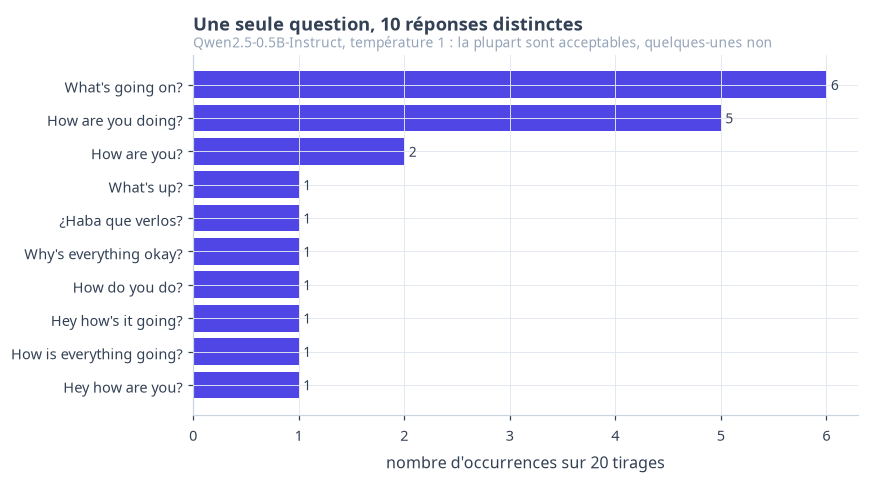

In [2]:
sorties = [llm.chat("Translate into English, answer with the translation only: « Comment ça va ? »",
                    temperature=1.0, seed=s, max_new_tokens=15) for s in range(20)]
comptes = pd.Series([s.strip().strip('"').strip("«» ") for s in sorties]).value_counts()
fig, ax = plt.subplots(figsize=(8, 0.35 * len(comptes) + 1))
ax.barh(comptes.index[::-1], comptes.values[::-1], color=INDIGO)
ax.set_xlabel("nombre d'occurrences sur 20 tirages")
ax.set_title(f"Une seule question, {len(comptes)} réponses distinctes")
subtitle(ax, "Qwen2.5-0.5B-Instruct, température 1 : la plupart sont acceptables, quelques-unes non")
annotate_bars(ax, "{:.0f}")
plt.tight_layout(); plt.show()

Même pour une phrase de trois mots, la liste des réponses valides n'est pas fermée (le
petit modèle produit aussi quelques sorties fausses ou hors sujet, qu'il faudra savoir
détecter) : une
évaluation par comparaison à « la » bonne réponse marquerait faux des sorties
parfaitement correctes. Pour un résumé ou un programme, l'espace explose.

**La saturation des benchmarks.** Un benchmark est saturé lorsqu'un modèle y atteint le
score maximal (ou le plafond humain) : il ne discrimine plus. Le livre cite plusieurs
remplacements successifs ; la figure les replace sur une frise.

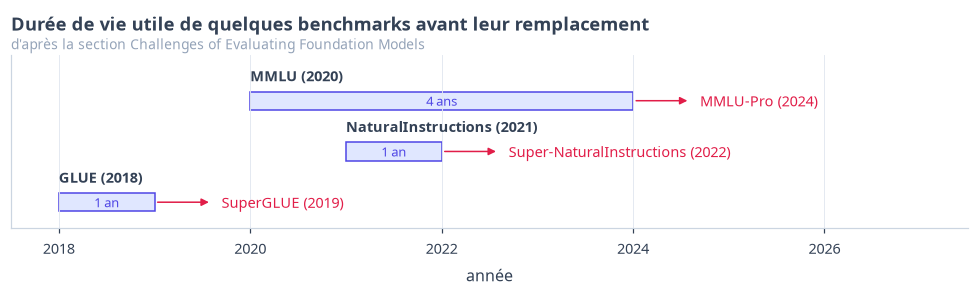

In [3]:
bench = [("GLUE", 2018, 2019, "SuperGLUE"), ("NaturalInstructions", 2021, 2022, "Super-NaturalInstructions"),
         ("MMLU", 2020, 2024, "MMLU-Pro")]
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, (nom, debut, fin, succ) in enumerate(bench):
    ax.barh(i, fin - debut, left=debut, color=LIGHT[INDIGO], edgecolor=INDIGO, height=0.36)
    ax.text(debut, i + 0.3, f"{nom} ({debut})", va="bottom", fontsize=9.5, fontweight="bold", color=SLATE)
    ax.text(debut + (fin - debut) / 2, i, f"{fin - debut} an" + ("s" if fin - debut > 1 else ""),
            ha="center", va="center", fontsize=8.5, color=INDIGO)
    ax.annotate("", xy=(fin + 0.6, i), xytext=(fin, i), arrowprops=dict(arrowstyle="-|>", color=ROSE))
    ax.text(fin + 0.7, i, f"{succ} ({fin})", va="center", fontsize=9.5, color=ROSE)
ax.set_yticks([]); ax.set_ylim(-0.5, len(bench) - 0.1); ax.set_xlim(2017.5, 2027.5); ax.set_xlabel("année")
ax.set_title("Durée de vie utile de quelques benchmarks avant leur remplacement")
subtitle(ax, "d'après la section Challenges of Evaluating Foundation Models")
plt.tight_layout(); plt.show()

**Carte du chapitre.** Le livre classe les méthodes automatiques en deux familles :
l'évaluation **exacte** (le verdict ne dépend pas de qui évalue) et l'évaluation
**subjective** (le score dépend du juge). Les métriques de modélisation du langage
servent de *proxy* en amont. Le diagramme ci-dessous sert de fil conducteur aux quatre
notebooks de cours.

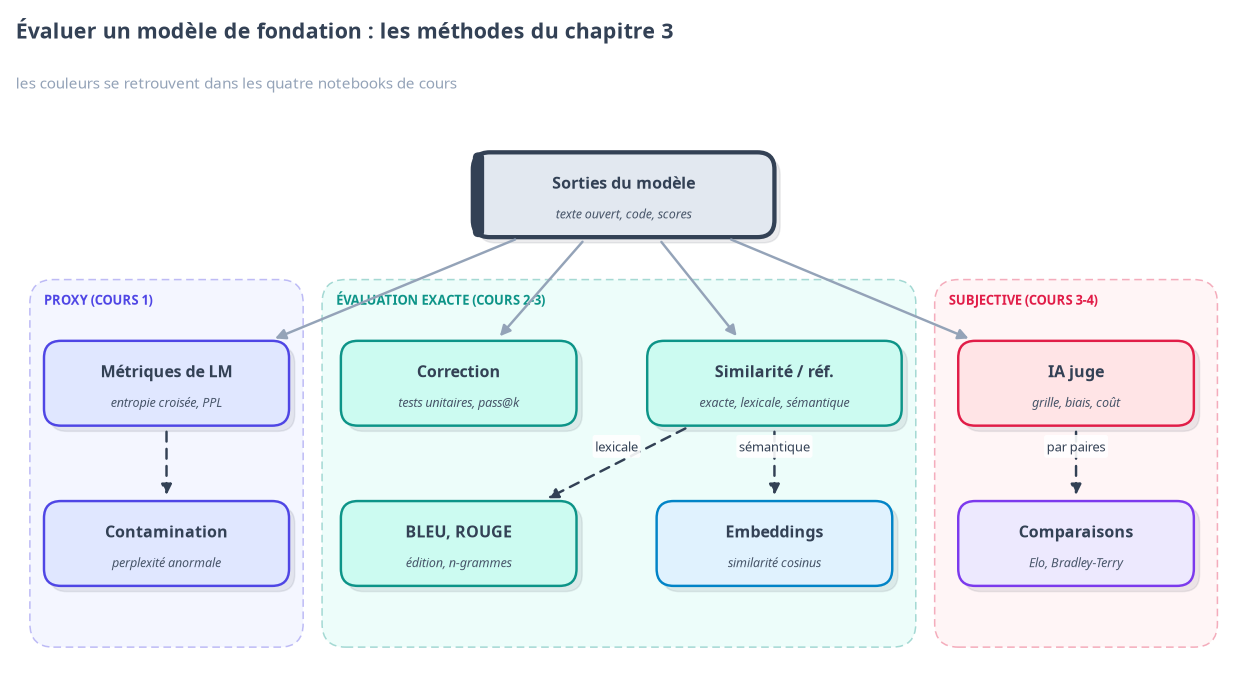

In [4]:
d = Diagram(13, 6.0, title="Évaluer un modèle de fondation : les méthodes du chapitre 3",
            subtitle="les couleurs se retrouvent dans les quatre notebooks de cours")
d.box("root", 6.5, 5.0, "Sorties du modèle", sub="texte ouvert, code, scores", color=SLATE, w=3.2, kind="model")
d.group(0.2, 0.2, 3.1, 4.1, "proxy (cours 1)", INDIGO)
d.group(3.3, 0.2, 9.6, 4.1, "évaluation exacte (cours 2-3)", TEAL)
d.group(9.8, 0.2, 12.8, 4.1, "subjective (cours 3-4)", ROSE)
d.box("lm", 1.65, 3.0, "Métriques de LM", sub="entropie croisée, PPL", color=INDIGO, w=2.6)
d.box("cont", 1.65, 1.3, "Contamination", sub="perplexité anormale", color=INDIGO, w=2.6)
d.box("fc", 4.75, 3.0, "Correction", sub="tests unitaires, pass@k", color=TEAL, w=2.5)
d.box("sim", 8.1, 3.0, "Similarité / réf.", sub="exacte, lexicale, sémantique", color=TEAL, w=2.7)
d.box("emb", 8.1, 1.3, "Embeddings", sub="similarité cosinus", color=SKY, w=2.5)
d.box("bleu", 4.75, 1.3, "BLEU, ROUGE", sub="édition, n-grammes", color=TEAL, w=2.5)
d.box("judge", 11.3, 3.0, "IA juge", sub="grille, biais, coût", color=ROSE, w=2.5)
d.box("cmp", 11.3, 1.3, "Comparaisons", sub="Elo, Bradley-Terry", color=VIOLET, w=2.5)
for n in ["lm", "fc", "sim", "judge"]:
    d.arrow("root", n, color=GRAY)
d.arrow("lm", "cont", style="dashed")
d.arrow("sim", "bleu", "lexicale", style="dashed")
d.arrow("sim", "emb", "sémantique", style="dashed")
d.arrow("judge", "cmp", "par paires", style="dashed")
d.show()

> **À retenir.** Les sorties ouvertes, l'intelligence croissante des modèles, leur
> opacité et la saturation rapide des benchmarks rendent l'évaluation des modèles de
> fondation plus difficile que celle du ML classique. Le chapitre propose une boîte à
> outils : métriques de modélisation du langage (proxy), évaluation exacte (tests,
> similarité) et évaluation subjective (juges IA, comparaisons).

## 2. Entropie : l'information moyenne d'un token (section *Entropy*)

**Motivation.** Avant de mesurer la qualité d'un modèle de langage, il faut savoir à quel
point le langage lui-même est prévisible. C'est ce que mesure l'**entropie**
(Shannon, 1948-1951).

**Définition.** Pour une variable $X$ de loi $P$ sur un vocabulaire $\mathcal V$ :
$$H(P) = -\sum_{x \in \mathcal V} P(x)\,\log_2 P(x) = \mathbb E_{x\sim P}\big[-\log_2 P(x)\big].$$
La quantité $-\log_2 P(x)$ est la **surprise** (ou information) du symbole $x$ : un
événement certain ne surprend pas (0 bit), un événement de probabilité $1/2$ apporte
1 bit, un événement de probabilité $1/1024$ apporte 10 bits. L'entropie est la surprise
moyenne.

**L'exemple du carré.** Le livre décrit deux « langues » pour désigner une position dans
un carré : (a) deux tokens *haut* / *bas*, (b) quatre tokens *haut-gauche*, *haut-droite*,
*bas-gauche*, *bas-droite*. Si les positions sont uniformes, la langue (a) a une
entropie de 1 bit, la langue (b) de 2 bits : chaque token de (b) est plus informatif,
mais plus difficile à prédire.

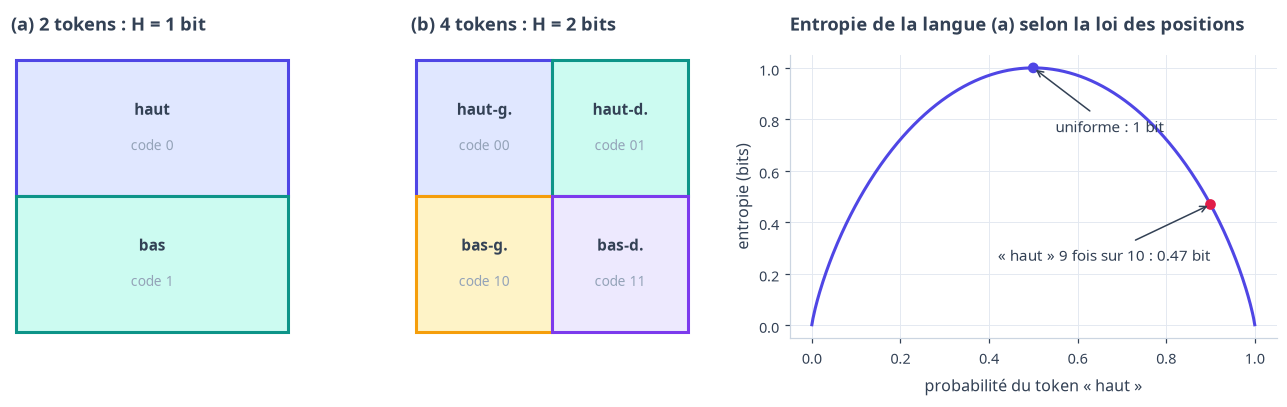

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))
for ax, (titre, cases) in zip(axes[:2], [
        ("(a) 2 tokens : H = 1 bit", [((0, 0.5), 1, 0.5, "haut", "0"), ((0, 0), 1, 0.5, "bas", "1")]),
        ("(b) 4 tokens : H = 2 bits", [((0, 0.5), 0.5, 0.5, "haut-g.", "00"), ((0.5, 0.5), 0.5, 0.5, "haut-d.", "01"),
                                       ((0, 0), 0.5, 0.5, "bas-g.", "10"), ((0.5, 0), 0.5, 0.5, "bas-d.", "11")])]):
    for k, ((x, y), w, h, nom, code) in enumerate(cases):
        c = [INDIGO, TEAL, AMBER, VIOLET][k]
        ax.add_patch(Rectangle((x, y), w, h, facecolor=LIGHT[c], edgecolor=c, lw=2))
        ax.text(x + w / 2, y + h / 2 + 0.05, nom, ha="center", fontsize=10, fontweight="bold", color=SLATE)
        ax.text(x + w / 2, y + h / 2 - 0.08, f"code {code}", ha="center", fontsize=9, color=GRAY)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(titre)
p = np.linspace(1e-4, 1 - 1e-4, 400)
axes[2].plot(p, [ev.entropy([q, 1 - q]) for q in p], color=INDIGO)
axes[2].scatter([0.5, 0.9], [1, ev.entropy([0.9, 0.1])], color=[INDIGO, ROSE], zorder=3)
axes[2].annotate("uniforme : 1 bit", (0.5, 1), (0.55, 0.75), arrowprops=dict(arrowstyle="->", color=SLATE))
axes[2].annotate(f"« haut » 9 fois sur 10 : {ev.entropy([0.9, 0.1]):.2f} bit", (0.9, ev.entropy([0.9, 0.1])),
                 (0.42, 0.25), arrowprops=dict(arrowstyle="->", color=SLATE))
axes[2].set_xlabel("probabilité du token « haut »"); axes[2].set_ylabel("entropie (bits)")
axes[2].set_title("Entropie de la langue (a) selon la loi des positions")
finish(fig)
plt.show()

La courbe de droite montre la seconde intuition du livre : l'entropie mesure la
**difficulté de prédire** le prochain token. Si l'on sait que la position est « en
haut » 9 fois sur 10, un token n'apporte plus que 0,47 bit en moyenne. À la limite, si
l'on peut prédire parfaitement ce que l'autre va dire, ce qu'il dit ne contient aucune
information.

**Propriétés utiles** (démontrées dans l'exercice 3.1) :
$0 \le H(P) \le \log_2 |\mathcal V|$, avec égalité à droite si et seulement si $P$ est
uniforme. Pour un vocabulaire de 151 643 tokens (Qwen2.5), l'entropie maximale est
$\log_2 151\,643 \approx 17{,}2$ bits par token.

In [6]:
V = 151_643
langues = {"(a) 2 positions": [0.5, 0.5], "(b) 4 positions": [0.25] * 4, "(b) non uniforme": [0.7, 0.1, 0.1, 0.1],
           "dé à 6 faces": [1 / 6] * 6, "anglais par lettre (estimation de Shannon)": None}
tab = pd.DataFrame({"entropie (bits)": [ev.entropy(p) if p else 1.0 for p in langues.values()]}, index=langues.keys())
tab.loc["vocabulaire Qwen, uniforme"] = math.log2(V)
tab

,entropie (bits)
(a) 2 positions,1.000
(b) 4 positions,2.000
(b) non uniforme,1.357
dé à 6 faces,2.585
anglais par lettre (estimation de Shannon),1.000
"vocabulaire Qwen, uniforme",17.210


> **À retenir.** L'entropie $H(P) = -\sum P \log_2 P$ est le nombre moyen de bits
> nécessaires pour coder un token avec un code optimal. Elle est d'autant plus grande que
> la langue est imprévisible, et maximale ($\log_2|\mathcal V|$) pour une loi uniforme.

## 3. Entropie croisée et divergence KL (section *Cross Entropy*)

**Motivation.** On ne connaît jamais la vraie loi $P$ du langage : on dispose d'un
modèle $Q$ appris sur des données. L'**entropie croisée** mesure le coût moyen (en bits)
de coder des données de loi $P$ avec un code optimisé pour $Q$ :
$$H(P, Q) = -\sum_x P(x)\,\log_2 Q(x) = \mathbb E_{x\sim P}\big[-\log_2 Q(x)\big].$$
Sur un jeu de données $x_1, \dots, x_N$ tiré de $P$, on l'estime par la moyenne empirique
$-\frac1N \sum_i \log_2 Q(x_i \mid x_{<i})$ : c'est exactement la **fonction de perte**
d'entraînement d'un modèle de langage (log-vraisemblance négative moyenne).

**Décomposition** (le livre l'énonce, démontrons-la). En ajoutant et retranchant
$\log P(x)$ :
$$H(P, Q) = -\sum_x P(x)\log P(x) + \sum_x P(x)\log\frac{P(x)}{Q(x)} = H(P) + D_{KL}(P\,\|\,Q).$$

**La KL est positive (inégalité de Gibbs).** Par concavité du logarithme (inégalité de
Jensen), $-D_{KL}(P\|Q) = \sum_x P(x) \log \frac{Q(x)}{P(x)} \le \log \sum_x P(x)\frac{Q(x)}{P(x)} = \log \sum_x Q(x) \le \log 1 = 0.$
Donc $D_{KL} \ge 0$, avec égalité si et seulement si $Q = P$. Conséquence :
$H(P, Q) \ge H(P)$. **Aucun modèle ne peut descendre sous l'entropie des données** ; un
modèle parfait l'atteint exactement. L'entropie croisée d'un modèle est donc son
approximation (par excès) de l'entropie de ses données. $\blacksquare$

**Vérification numérique** sur des lois aléatoires, puis visualisation : pour une langue
à deux tokens de vraie loi $P = (0{,}7 ; 0{,}3)$, l'entropie croisée d'un modèle
$Q = (q ; 1-q)$ est minimale en $q = 0{,}7$ et vaut alors $H(P)$.

In [7]:
rng = np.random.default_rng(0)
lignes = []
for _ in range(5):
    P, Q = rng.dirichlet(np.ones(5)), rng.dirichlet(np.ones(5))
    lignes.append(dict(H_P=ev.entropy(P), KL_PQ=ev.kl_divergence(P, Q), H_PQ=ev.cross_entropy(P, Q),
                       H_QP=ev.cross_entropy(Q, P)))
df = pd.DataFrame(lignes)
df["H_P + KL"] = df.H_P + df.KL_PQ
df.round(4)

,H_P,KL_PQ,H_PQ,H_QP,H_P + KL
0,1.605,1.390,2.994,4.127,2.994
1,1.529,1.642,3.170,7.520,3.170
2,1.738,0.920,2.658,2.641,2.658
3,2.140,0.349,2.490,2.289,2.490
4,2.004,0.821,2.824,2.563,2.824


Les colonnes `H_PQ` et `H_P + KL` coïncident, et `H_PQ` diffère de `H_QP` : l'entropie
croisée **n'est pas symétrique**, comme le souligne le livre.

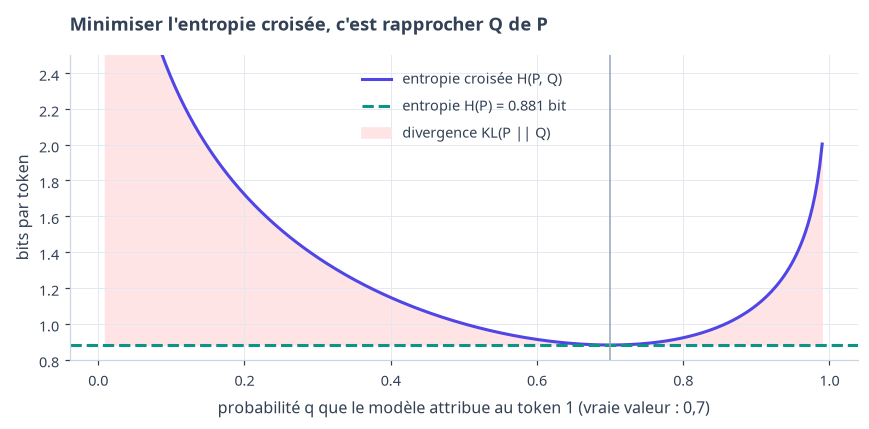

In [8]:
pv = 0.7
q = np.linspace(0.01, 0.99, 300)
ce = np.array([ev.cross_entropy([pv, 1 - pv], [x, 1 - x]) for x in q])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(q, ce, color=INDIGO, label="entropie croisée H(P, Q)")
ax.axhline(ev.entropy([pv, 1 - pv]), color=TEAL, ls="--", label=f"entropie H(P) = {ev.entropy([pv, 1 - pv]):.3f} bit")
ax.fill_between(q, ev.entropy([pv, 1 - pv]), ce, color=LIGHT[ROSE], label="divergence KL(P || Q)")
ax.axvline(pv, color=GRAY, lw=1)
ax.set_ylim(0.8, 2.5)
ax.set_xlabel("probabilité q que le modèle attribue au token 1 (vraie valeur : 0,7)")
ax.set_ylabel("bits par token")
ax.set_title("Minimiser l'entropie croisée, c'est rapprocher Q de P")
ax.legend(loc="upper center")
plt.tight_layout(); plt.show()

> **À retenir.** L'entropie croisée d'un modèle sur des données dépend de deux choses :
> la prévisibilité des données ($H(P)$) et l'écart du modèle à la vraie loi
> ($D_{KL}(P\|Q) \ge 0$). Entraîner un modèle de langage, c'est minimiser cette entropie
> croisée, donc la KL.

## 4. Bits par caractère, bits par octet et perplexité (sections *Bits-per-Character and Bits-per-Byte* et *Perplexity*)

**Le problème des unités.** Une entropie croisée de 3 bits par token ne veut rien dire
seule : un modèle qui découpe en mots et un modèle qui découpe en caractères n'ont pas le
même « token ». Le livre présente donc quatre métriques, toutes liées :

- $\mathrm{CE}$ : entropie croisée par token (en **nats** si l'on utilise $\ln$, comme
  PyTorch, ou en **bits** avec $\log_2$) ; $1$ nat $= 1/\ln 2 \approx 1{,}443$ bit ;
- $\mathrm{BPC} = \dfrac{\mathrm{CE}_{\text{bits}}}{\text{caractères par token}}$ ;
- $\mathrm{BPB} = \dfrac{\mathrm{BPC}}{\text{octets par caractère}}$ (indépendant du
  tokenizer **et** de l'encodage des caractères) ;
- $\mathrm{PPL} = 2^{\mathrm{CE}_{\text{bits}}} = e^{\mathrm{CE}_{\text{nats}}}$.

**Démonstration des liens.** Soit un texte de $N$ tokens, $C$ caractères et $B$ octets,
et $L = -\sum_{i} \ln Q(x_i \mid x_{<i})$ sa log-vraisemblance négative totale (nats).
Alors $\mathrm{CE}_{\text{nats}} = L/N$, $\mathrm{CE}_{\text{bits}} = L/(N \ln 2)$,
$\mathrm{BPC} = L/(C\ln 2) = \mathrm{CE}_{\text{bits}} \cdot N/C$ et
$\mathrm{BPB} = L/(B\ln 2) = \mathrm{BPC}\cdot C/B$. Enfin
$2^{L/(N\ln 2)} = e^{L/N}$ : la perplexité ne dépend **pas** de la base choisie, c'est
l'une des raisons pour lesquelles on la publie plus volontiers que l'entropie croisée.
Les quatre métriques sont donc des réécritures d'une même quantité $L$ : connaître
l'une et les rapports $N/C$, $C/B$ suffit pour retrouver les autres. $\blacksquare$

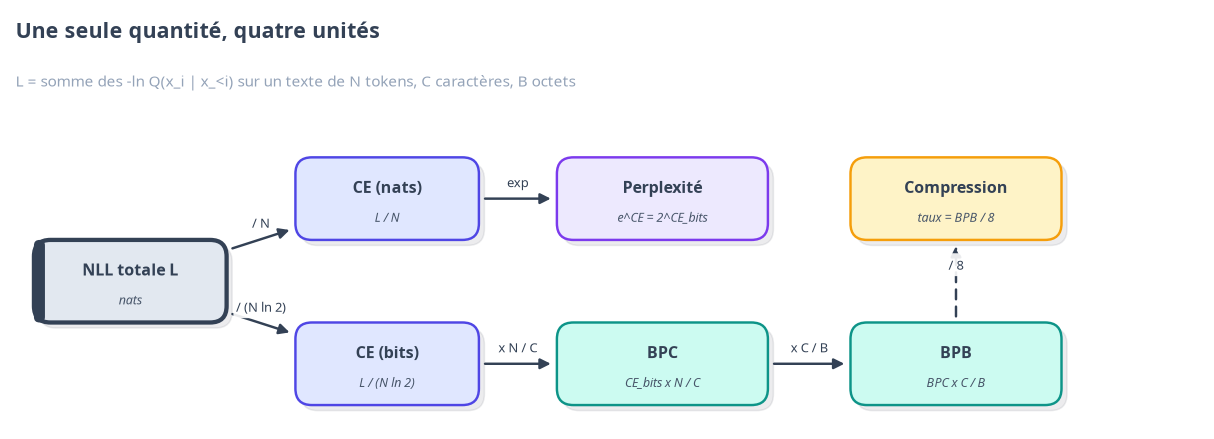

In [9]:
d = Diagram(13, 3.6, title="Une seule quantité, quatre unités",
            subtitle="L = somme des -ln Q(x_i | x_<i) sur un texte de N tokens, C caractères, B octets")
d.box("L", 1.3, 1.6, "NLL totale L", sub="nats", color=SLATE, w=2.1, kind="model")
d.box("ce", 4.1, 2.5, "CE (nats)", sub="L / N", color=INDIGO, w=2.0)
d.box("ceb", 4.1, 0.7, "CE (bits)", sub="L / (N ln 2)", color=INDIGO, w=2.0)
d.box("ppl", 7.1, 2.5, "Perplexité", sub="e^CE = 2^CE_bits", color=VIOLET, w=2.3)
d.box("bpc", 7.1, 0.7, "BPC", sub="CE_bits x N / C", color=TEAL, w=2.3)
d.box("bpb", 10.3, 0.7, "BPB", sub="BPC x C / B", color=TEAL, w=2.3)
d.box("zip", 10.3, 2.5, "Compression", sub="taux = BPB / 8", color=AMBER, w=2.3)
d.arrow("L", "ce", "/ N"); d.arrow("L", "ceb", "/ (N ln 2)")
d.arrow("ce", "ppl", "exp"); d.arrow("ceb", "bpc", "x N / C"); d.arrow("bpc", "bpb", "x C / B")
d.arrow("bpb", "zip", "/ 8", style="dashed")
d.show()

**L'exemple chiffré du livre**, refait pas à pas : 6 bits par token, 2 caractères par
token et des caractères ASCII codés sur 7 bits (soit 7/8 d'octet).

In [10]:
bits_tok = 6
bpc = ev.bpc_from_bits_per_token(bits_tok, chars_per_token=2)
bpb = ev.bpb_from_bpc(bpc, bytes_per_char=7 / 8)
pd.Series({"bits par token": bits_tok, "BPC": bpc, "BPB": round(bpb, 3),
           "perplexité par token (2^6)": ev.perplexity_from_ce(bits_tok, "bits"),
           "taille compressée / taille brute": f"{bpb / 8:.1%}"}).to_frame("valeur")

,valeur
bits par token,6
BPC,3.0
BPB,3.429
perplexité par token (2^6),64.0
taille compressée / taille brute,42.9%


**Perplexité = facteur de branchement effectif.** Si le modèle hésitait uniformément
entre $K$ tokens à chaque pas, son entropie croisée serait $\log_2 K$ et sa perplexité
exactement $K$. Une perplexité de 4 signifie « aussi incertain qu'un choix uniforme entre
4 options » (le carré (b) du livre). La figure illustre que des lois très différentes
peuvent avoir la même perplexité : seule compte l'incertitude « effective ».

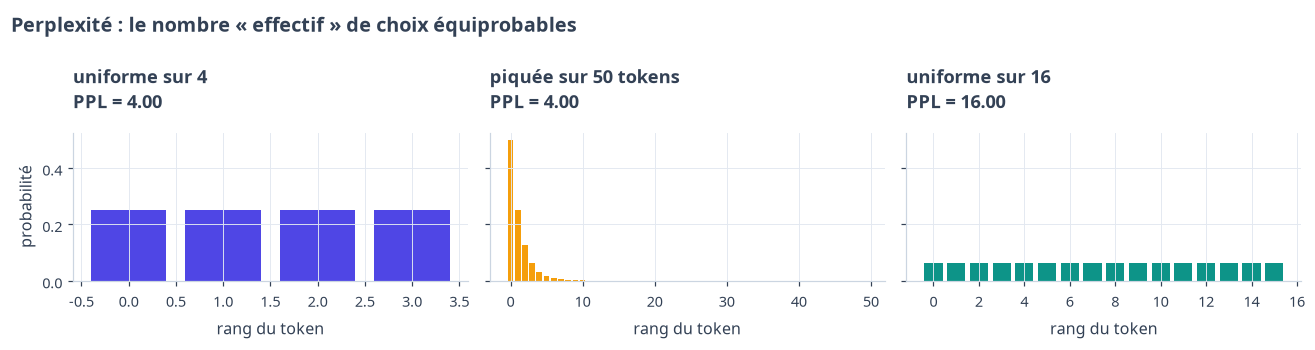

In [11]:
lois = {"uniforme sur 4": np.full(4, 0.25), "piquée sur 50 tokens": None, "uniforme sur 16": np.full(16, 1 / 16)}
# loi à 50 tokens dont la perplexité vaut 4 : on cherche la température qui donne H = 2 bits
z = -np.arange(50, dtype=float)
lo, hi = 0.01, 50.0
for _ in range(60):  # dichotomie sur la température (l'entropie croît avec T)
    T = (lo + hi) / 2
    if ev.entropy(llm.softmax(z, T)) > 2:
        hi = T
    else:
        lo = T
lois["piquée sur 50 tokens"] = llm.softmax(z, T)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (nom, p), c in zip(axes, lois.items(), [INDIGO, AMBER, TEAL]):
    ax.bar(np.arange(len(p)), p, color=c)
    ax.set_title(f"{nom}\nPPL = {2 ** ev.entropy(p):.2f}")
    ax.set_xlabel("rang du token")
axes[0].set_ylabel("probabilité")
finish(fig, "Perplexité : le nombre « effectif » de choix équiprobables")
plt.show()

**Le lien avec la compression.** Un modèle de langage couplé à un codeur arithmétique
compresse un texte en environ $L/\ln 2$ bits. Un BPB de 1 signifie que chaque octet
(8 bits) est représenté par 1 bit : un taux de compression de 8. Le tableau 3-1 du livre
reporte d'ailleurs le BPB de GPT-2 sur enwik8 (de 1,16 pour 117 M paramètres à 0,93 pour
1,5 G) : mieux prédire, c'est mieux compresser.

> **À retenir.** Entropie croisée, BPC, BPB et perplexité sont quatre écritures de la même
> log-vraisemblance négative. La perplexité ne dépend pas de la base du logarithme et
> s'interprète comme un nombre effectif de choix ; le BPB est la seule métrique
> comparable entre tokenizers différents.

## 5. Mesurer ces métriques sur GPT-2 et Qwen (encadré *How to Use a Language Model to Compute a Text's Perplexity*)

Pour un texte $x_1, \dots, x_n$, la perplexité d'un modèle est
$$\mathrm{PPL} = P(x_1, \dots, x_n)^{-1/n} = \Big(\prod_{i=1}^{n} \frac{1}{P(x_i \mid x_1, \dots, x_{i-1})}\Big)^{1/n},$$
la moyenne **géométrique** des inverses des probabilités conditionnelles. Il faut donc
accéder aux log-probabilités de chaque token, ce que toutes les API commerciales ne
fournissent pas (chapitre 2). Le schéma ci-dessous décrit le calcul fait par
`ev.text_metrics` ; un token de début `<|endoftext|>` est ajouté pour que le premier
token du texte soit lui aussi prédit.

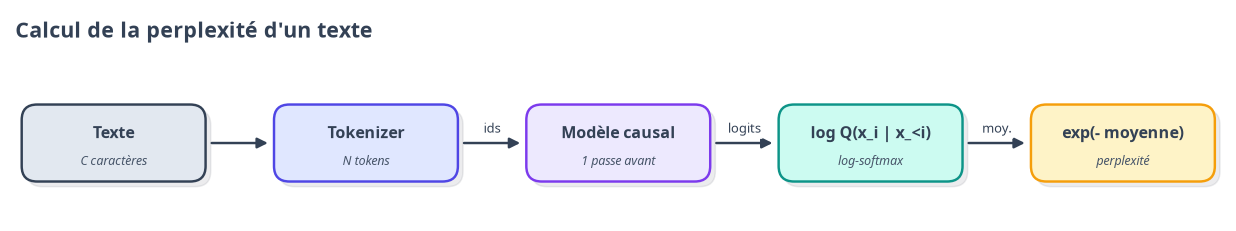

In [12]:
d = Diagram(14.2, 1.9, title="Calcul de la perplexité d'un texte")
d.flow([("t", "Texte", "C caractères"), ("tok", "Tokenizer", "N tokens"), ("m", "Modèle causal", "1 passe avant"),
        ("lp", "log Q(x_i | x_<i)", "log-softmax"), ("ppl", "exp(- moyenne)", "perplexité")],
       y=0.9, x0=1.2, dx=2.95, w=2.15, labels=["", "ids", "logits", "moy."],
       colors=[SLATE, INDIGO, VIOLET, TEAL, AMBER])
d.show()

Voyons la **surprise** token par token sur une phrase, pour GPT-2. Les tokens prévisibles
(fin d'un mot, mot grammatical attendu) coûtent peu ; les tokens informatifs (le sujet,
un nom propre) coûtent cher.

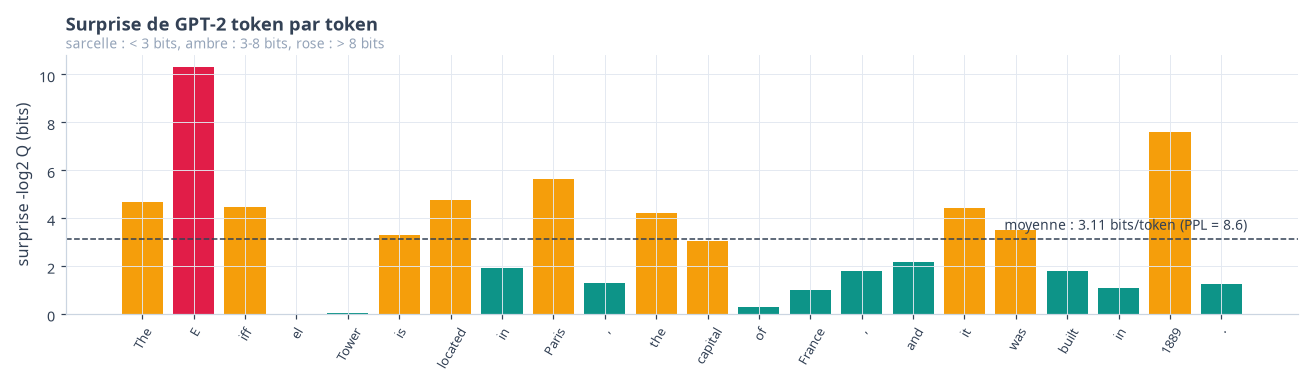

In [13]:
phrase = "The Eiffel Tower is located in Paris, the capital of France, and it was built in 1889."
m = ev.text_metrics(phrase, llm.BASE)
surprise = -m.logprobs / math.log(2)
fig, ax = plt.subplots(figsize=(12, 3.6))
cols = [ROSE if s > 8 else (AMBER if s > 3 else TEAL) for s in surprise]
ax.bar(range(m.n_tokens), surprise, color=cols)
ax.set_xticks(range(m.n_tokens)); ax.set_xticklabels([repr(t)[1:-1] for t in m.tokens], rotation=60, fontsize=8.5)
ax.axhline(m.ce_bits, color=SLATE, ls="--", lw=1)
ax.text(m.n_tokens - 0.5, m.ce_bits + 0.4, f"moyenne : {m.ce_bits:.2f} bits/token (PPL = {m.ppl:.1f})",
        ha="right", fontsize=9)
ax.set_ylabel("surprise -log2 Q (bits)")
ax.set_title("Surprise de GPT-2 token par token")
subtitle(ax, "sarcelle : < 3 bits, ambre : 3-8 bits, rose : > 8 bits")
plt.tight_layout(); plt.show()

Vérifions la cohérence avec la fonction du socle `llm.perplexity` (qui, elle, ne prédit
pas le premier token) et l'égalité des définitions « exponentielle de la moyenne » et
« moyenne géométrique des inverses ».

In [14]:
p_tok = np.exp(m.logprobs)
pd.Series({"exp(-moyenne des log p)": m.ppl,
           "moyenne géométrique des 1/p": float(np.prod(1 / p_tok) ** (1 / len(p_tok))),
           "2^(CE en bits)": 2 ** m.ce_bits,
           "llm.perplexity (sans le 1er token)": llm.perplexity(phrase, llm.BASE)}).to_frame("perplexité")

,perplexité
exp(-moyenne des log p),8.621
moyenne géométrique des 1/p,8.621
2^(CE en bits),8.621
llm.perplexity (sans le 1er token),9.595


**Comparer trois modèles sur le même texte.** GPT-2 et Qwen2.5 n'ont pas le même
tokenizer : leurs perplexités **par token** ne sont pas directement comparables (Qwen
découpe ce texte français en moins de tokens, chaque token porte plus d'information). Le
BPB, lui, est rapporté à l'octet de texte et se compare honnêtement.

In [15]:
texte_fr = ("Le petit village se réveille lentement : la boulangère ouvre sa boutique, les enfants partent "
            "à l'école et le facteur distribue le courrier en saluant chaque habitant.")
tab = pd.DataFrame([ev.text_metrics(texte_fr, mid).as_dict() for mid in MODELES.values()], index=MODELES.keys())
tab[["tokens", "caracteres", "octets", "ce_bits", "ppl", "bpc", "bpb"]]

,tokens,caracteres,octets,ce_bits,ppl,bpc,bpb
GPT-2 (124 M),53,167,171,6.642,99.895,2.108,2.059
Qwen2.5-0.5B base,43,167,171,4.946,30.823,1.274,1.244
Qwen2.5-0.5B Instruct,43,167,171,5.040,32.890,1.298,1.267


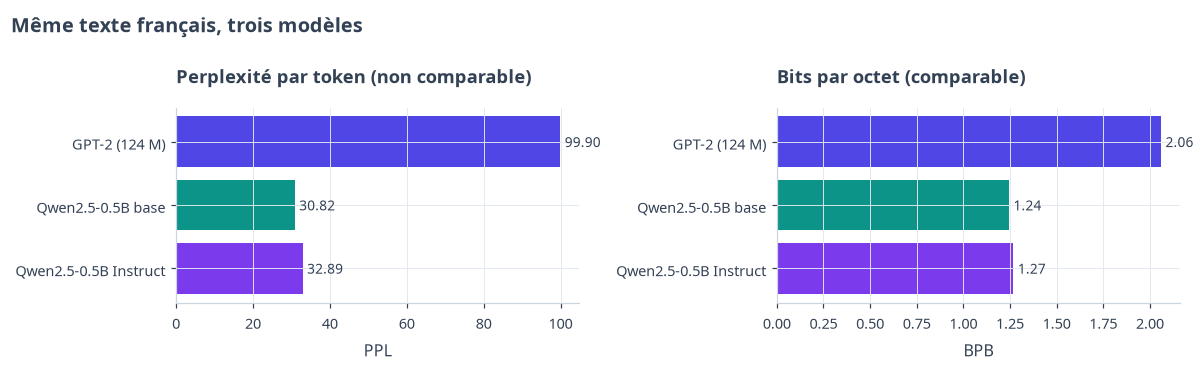

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, titre in [(axes[0], "ppl", "Perplexité par token (non comparable)"),
                       (axes[1], "bpb", "Bits par octet (comparable)")]:
    ax.barh(tab.index[::-1], tab[col][::-1], color=[VIOLET, TEAL, INDIGO])
    ax.set_title(titre); annotate_bars(ax, "{:.2f}")
axes[0].set_xlabel("PPL"); axes[1].set_xlabel("BPB")
finish(fig, "Même texte français, trois modèles")
plt.show()

GPT-2 a été entraîné presque uniquement sur de l'anglais : il découpe le français en
beaucoup de petits tokens, et son BPB est nettement plus élevé que celui de Qwen2.5,
multilingue. Remarquez aussi que la version *Instruct* de Qwen a un BPB légèrement plus
élevé que la version de base (on y revient en section 6).

> **À retenir.** Calculer une perplexité demande une seule passe avant et l'accès aux
> log-probabilités. Pour comparer des modèles aux tokenizers différents, on utilise le
> BPB (ou une perplexité par caractère), jamais la perplexité par token.

## 6. Interpréter une perplexité (section *Perplexity Interpretation and Use Cases*)

Le livre donne trois règles empiriques. Testons-les une à une.

**Règle 1 : des données plus structurées donnent une perplexité plus faible.** Une balise
`<head>` appelle une balise `</head>` ; une liste de nombres aléatoires n'appelle rien.

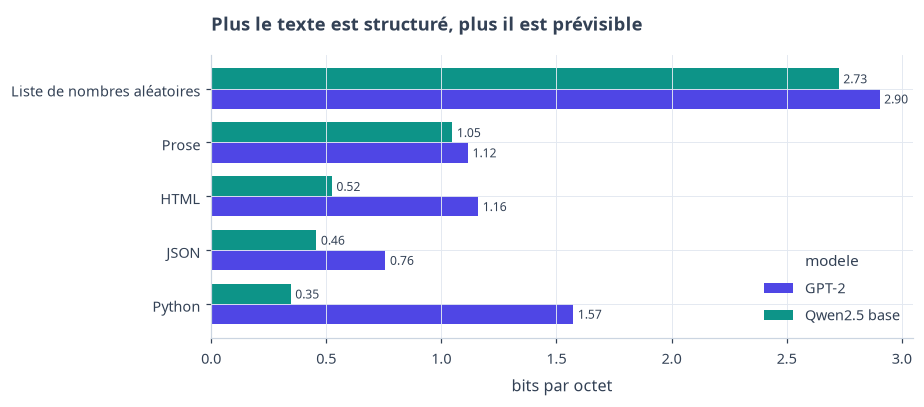

In [17]:
rows = []
for nom, txt in ev.STRUCTURED_TEXTS.items():
    for mod, mid in [("GPT-2", llm.BASE), ("Qwen2.5 base", QWEN_BASE)]:
        rows.append(dict(texte=nom, modele=mod, bpb=ev.text_metrics(txt, mid).bpb))
st = pd.DataFrame(rows).pivot(index="texte", columns="modele", values="bpb").sort_values("Qwen2.5 base")
ax = st.plot.barh(color=[INDIGO, TEAL], figsize=(8.5, 3.8), width=0.75)
ax.set_xlabel("bits par octet"); ax.set_ylabel("")
ax.set_title("Plus le texte est structuré, plus il est prévisible")
annotate_bars(ax, "{:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

Le code et le HTML sont beaucoup plus prévisibles que la prose ; la liste de nombres
aléatoires est la plus coûteuse (aucun modèle ne peut prévoir un tirage au sort).
Qwen2.5, entraîné sur beaucoup de code, gagne surtout sur les textes structurés.

**Règle 2 : plus de contexte donne une perplexité plus faible.** On mesure la surprise
moyenne des tokens d'un long texte lorsqu'on ne laisse au modèle que les $L$ derniers
tokens de contexte, pour $L = 1, 2, 4, \dots, 256$ (une fenêtre glissante par token
prédit). Le texte, inédit, est rédigé pour ce cours.

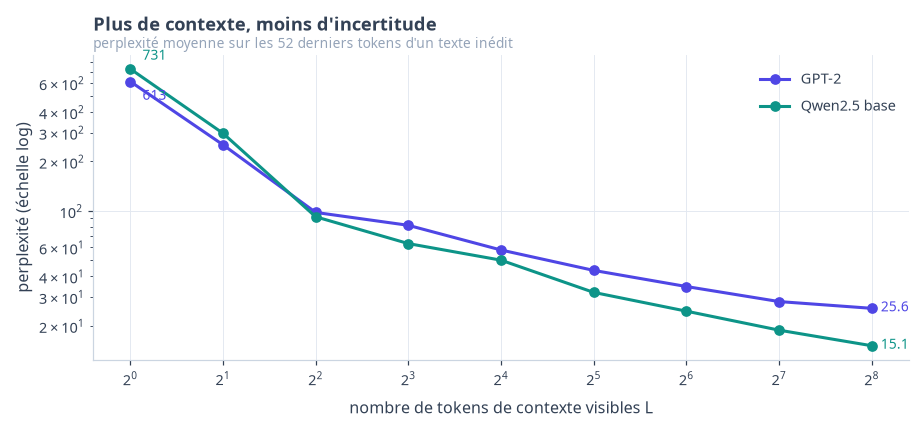

In [18]:
LONG = (
    "Every autumn the small coastal town of Pellmore organises a festival to celebrate the return of the "
    "fishing boats. The festival began more than a century ago, when the families of the fishermen gathered "
    "on the harbour to welcome the crews after the long summer at sea. Today the festival attracts visitors "
    "from the whole region. On the first day, the boats are decorated with flags and lanterns, and a parade "
    "of musicians walks from the church to the harbour. On the second day, the fishermen organise a race "
    "across the bay, and the winning crew receives a silver cup that is kept in the town hall for a year. "
    "On the third and last day, the whole town shares a long dinner on the harbour, where every family "
    "brings a dish prepared with fish caught during the season. The festival is also an occasion to remember "
    "the fishermen who did not come back from the sea. A short ceremony takes place at sunset near the old "
    "lighthouse, and the names of the missing sailors are read aloud by the youngest member of the crews. "
    "Many visitors say that this ceremony is the most moving moment of the festival. In recent years, the "
    "town council has tried to make the festival more sustainable. The lanterns now use small solar panels, "
    "the plastic cups have been replaced by glasses that visitors return at the end of the evening, and the "
    "dinner only serves fish from species that are not threatened. The organisers hope that the festival "
    "will continue for another century, and that the children of Pellmore will one day welcome their own "
    "boats on the harbour, just as their grandparents did.")


def surprise_par_contexte(texte, model_id, contextes, debut=260):
    import torch
    tok, model = llm.load(model_id)
    ids = torch.tensor(tok(texte)["input_ids"], device=model.device)
    cibles = range(debut, len(ids))
    res = {}
    for L in contextes:
        fen = torch.stack([ids[t - L:t] for t in cibles])
        with torch.no_grad():
            lp = torch.log_softmax(model(fen).logits[:, -1].float(), -1)
        res[L] = float(-lp[torch.arange(len(cibles)), ids[debut:]].mean() / math.log(2))
    return res, len(cibles)


contextes = [1, 2, 4, 8, 16, 32, 64, 128, 256]
fig, ax = plt.subplots(figsize=(8.5, 4))
for (nom, mid), c in zip([("GPT-2", llm.BASE), ("Qwen2.5 base", QWEN_BASE)], [INDIGO, TEAL]):
    res, n_cibles = surprise_par_contexte(LONG, mid, contextes)
    ax.plot(list(res), [2 ** v for v in res.values()], "o-", color=c, label=nom)
    ax.annotate(f"{2 ** res[256]:.1f}", (256, 2 ** res[256]), (6, -2), textcoords="offset points", color=c, fontsize=9)
    ax.annotate(f"{2 ** res[1]:.0f}", (1, 2 ** res[1]), (8, 6 if c == TEAL else -12), textcoords="offset points",
                color=c, fontsize=9)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("nombre de tokens de contexte visibles L"); ax.set_ylabel("perplexité (échelle log)")
ax.set_title("Plus de contexte, moins d'incertitude")
subtitle(ax, f"perplexité moyenne sur les {n_cibles} derniers tokens d'un texte inédit")
ax.legend()
plt.tight_layout(); plt.show()

Avec un seul token de contexte, le modèle ne dispose que d'une statistique de bigrammes :
la perplexité se compte en centaines. Elle chute rapidement jusqu'à quelques dizaines de
tokens puis continue de baisser plus lentement : Shannon conditionnait sur 10 tokens, les
modèles actuels sur des milliers.

Un cas extrême révèle la puissance du contexte : **répéter** un texte. La seconde copie
devient presque parfaitement prévisible, car le modèle sait recopier ce qu'il vient de
lire (mécanisme des « têtes d'induction »). Un texte présent dans le contexte se
comporte comme un texte mémorisé.

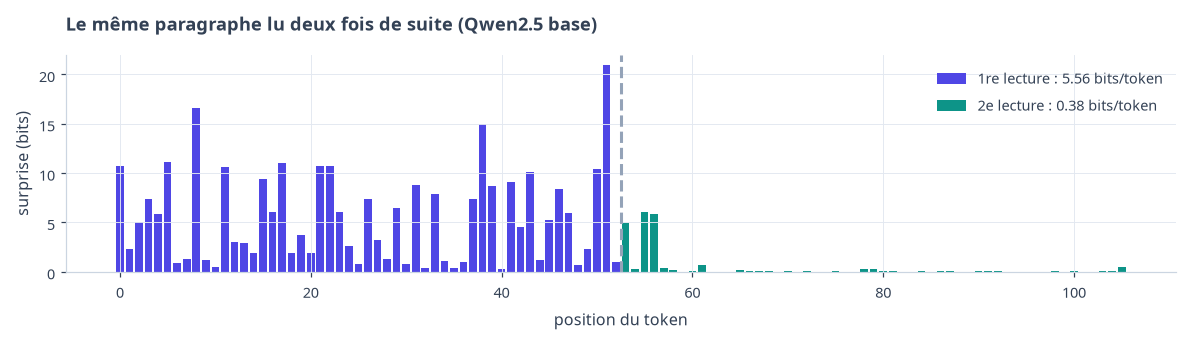

In [19]:
txt = ev.FRESH_TEXTS["Récit (inédit)"]
m2 = ev.text_metrics(txt + " " + txt, QWEN_BASE)
half = m2.n_tokens // 2
fig, ax = plt.subplots(figsize=(11, 3.2))
s = -m2.logprobs / math.log(2)
ax.bar(range(half), s[:half], color=INDIGO, label=f"1re lecture : {s[:half].mean():.2f} bits/token")
ax.bar(range(half, m2.n_tokens), s[half:], color=TEAL, label=f"2e lecture : {s[half:].mean():.2f} bits/token")
ax.axvline(half - 0.5, color=GRAY, ls="--")
ax.set_xlabel("position du token"); ax.set_ylabel("surprise (bits)")
ax.set_title("Le même paragraphe lu deux fois de suite (Qwen2.5 base)")
ax.legend()
plt.tight_layout(); plt.show()

**Règle 3 : un vocabulaire plus grand donne une perplexité plus élevée.** Pour un même
texte, prédire le prochain caractère (une centaine de choix) est plus facile que prédire
le prochain mot. On peut le vérifier en convertissant nos mesures : la perplexité par
caractère vaut $2^{\mathrm{BPC}}$, la perplexité par token $2^{\mathrm{CE}_{\text{bits}}}$.

In [20]:
r = []
for nom, txt in list(ev.FRESH_TEXTS.items())[:4]:
    m_ = ev.text_metrics(txt, QWEN_BASE)
    nmots = len(txt.split())
    r.append({"texte": nom, "PPL / caractère": m_.char_ppl, "PPL / token": m_.ppl,
              "PPL / mot": math.exp(m_.nll_nats / nmots), "caractères par token": m_.n_chars / m_.n_tokens})
pd.DataFrame(r).set_index("texte")

,PPL / caractère,PPL / token,PPL / mot,caractères par token
texte,,,,
Déclaration (inédite),2.355,99.729,147.548,5.373
Discours (inédit),2.195,54.074,109.919,5.075
Licence (inédite),2.053,39.137,49.217,5.098
Principes (inédits),2.567,187.578,548.877,5.553


Le même modèle, sur le même texte, affiche une perplexité d'environ 2 à 2,5 par caractère,
de quelques dizaines par token et plus élevée encore par mot : une perplexité n'a de sens
qu'accompagnée de son unité et du tokenizer.

**Post-entraînement.** Le livre signale que la perplexité augmente souvent après le
post-entraînement (SFT, RLHF) : le modèle apprend à accomplir des tâches plutôt qu'à
imiter la distribution du Web, et sa distribution se « concentre » (on parle d'entropie
effondrée). Comparons Qwen2.5-0.5B avant et après post-entraînement sur nos textes
inédits, et l'entropie de leur distribution du prochain token.

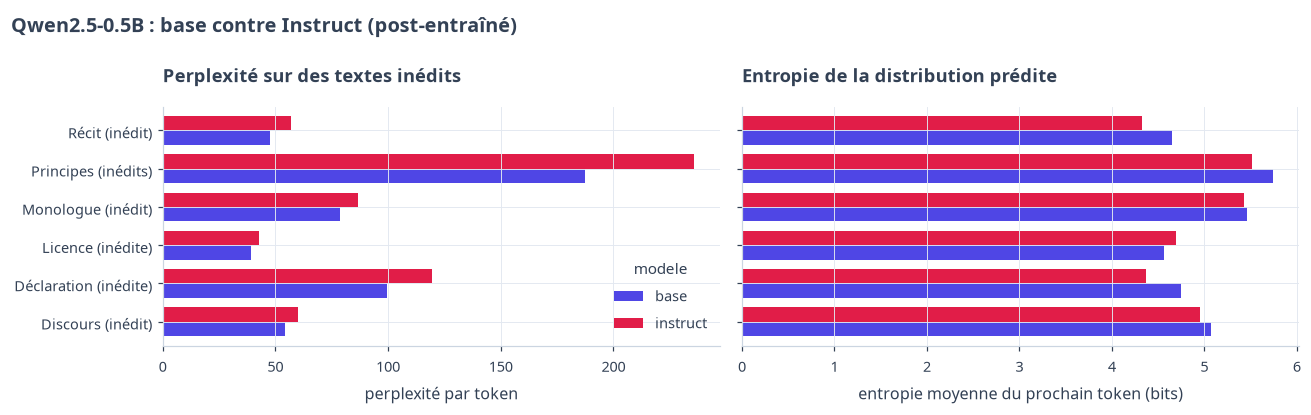

Rapport moyen des perplexités instruct / base : 1.16 ; entropie moyenne base = 5.04 bits, instruct = 4.88 bits


In [21]:
import torch


def entropie_moyenne(texte, model_id):
    tok, model = llm.load(model_id)
    ids = tok(texte, return_tensors="pt")["input_ids"].to(model.device)
    with torch.no_grad():
        p = torch.softmax(model(ids).logits[0].float(), -1)
    return float((-(p * torch.log2(p.clamp_min(1e-30))).sum(-1)).mean())


r = []
for nom, txt in ev.FRESH_TEXTS.items():
    for mod, mid in [("base", QWEN_BASE), ("instruct", llm.SMALL)]:
        r.append(dict(texte=nom, modele=mod, ppl=ev.text_metrics(txt, mid).ppl, entropie=entropie_moyenne(txt, mid)))
pt = pd.DataFrame(r)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
piv = pt.pivot(index="texte", columns="modele", values="ppl")
piv.plot.barh(ax=axes[0], color=[INDIGO, ROSE], width=0.75)
axes[0].set_xlabel("perplexité par token"); axes[0].set_ylabel(""); axes[0].set_title("Perplexité sur des textes inédits")
piv2 = pt.pivot(index="texte", columns="modele", values="entropie")
piv2.plot.barh(ax=axes[1], color=[INDIGO, ROSE], width=0.75, legend=False)
axes[1].set_xlabel("entropie moyenne du prochain token (bits)"); axes[1].set_ylabel(""); axes[1].set_yticklabels([])
axes[1].set_title("Entropie de la distribution prédite")
finish(fig, "Qwen2.5-0.5B : base contre Instruct (post-entraîné)")
plt.show()
print(f"Rapport moyen des perplexités instruct / base : {(piv.instruct / piv.base).mean():.2f} ; "
      f"entropie moyenne base = {piv2.base.mean():.2f} bits, instruct = {piv2.instruct.mean():.2f} bits")

Sur ces textes, le modèle post-entraîné est en moyenne un peu **plus** perplexe que le
modèle de base, alors que l'entropie de ses prédictions est en moyenne plus **basse** :
il est plus sûr de lui, mais ses certitudes ne correspondent plus aussi bien à la
distribution du texte ordinaire. Il est pourtant bien meilleur pour suivre des
instructions : la
perplexité est un bon proxy des capacités d'un modèle **pré-entraîné**, mais un mauvais
critère pour comparer des modèles post-entraînés (ou quantifiés, chapitre 7).

> **À retenir.** Une perplexité dépend des données (structure), du contexte disponible,
> de l'unité (caractère, token, mot) et du type de modèle (base ou post-entraîné). Elle ne
> se compare qu'à conditions égales.

## 7. Textes naturels, mélangés et mémorisés : détecter la contamination (section *Perplexity Interpretation and Use Cases*)

Deux usages de la perplexité décrits par le livre :

- elle est **la plus basse** pour les textes que le modèle a vus et mémorisés ; une
  perplexité anormalement basse sur un benchmark suggère une **contamination** (le
  benchmark était dans les données d'entraînement, ses scores ne sont plus fiables) ;
  même idée pour dédupliquer un corpus (n'ajouter que des textes de perplexité élevée) ;
- elle est **la plus haute** pour les textes imprévisibles ou incohérents (« home cat go
  eye ») : détection d'anomalies.

Nous comparons trois familles de textes (définies dans `aie/ch03_evaluation.py`) : six
textes célèbres du domaine public, reproduits des milliers de fois sur le Web
(**mémorisés**) ; six textes **inédits** rédigés pour ce cours, de même registre ; et les
textes célèbres aux mots **mélangés** (même vocabulaire, structure détruite).

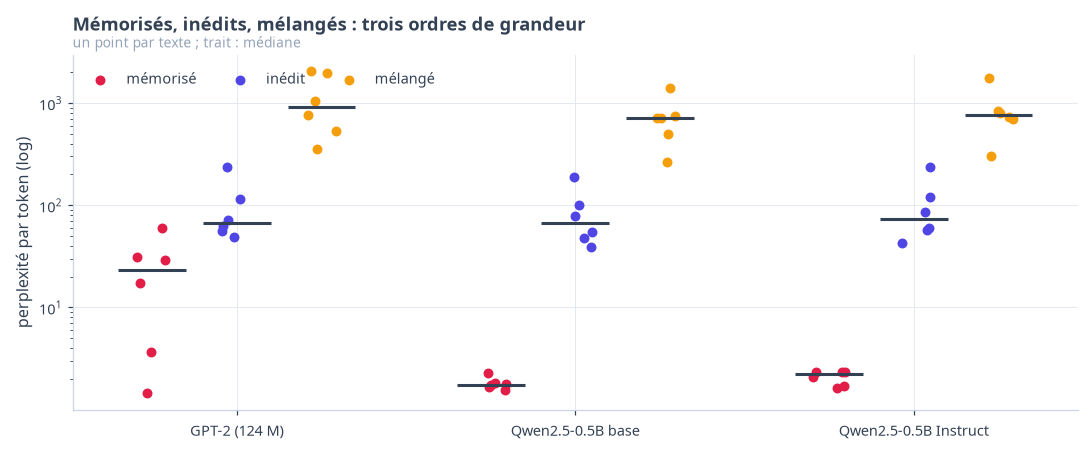

famille,inédit,mélangé,mémorisé
modele,,,
GPT-2 (124 M),67.2,908.0,23.2
Qwen2.5-0.5B Instruct,73.3,762.2,2.2
Qwen2.5-0.5B base,66.4,713.6,1.8


In [22]:
rows = []
for mod, mid in MODELES.items():
    for nom, txt in ev.MEMORIZED_TEXTS.items():
        for fam, t in [("mémorisé", txt), ("mélangé", ev.shuffle_words(txt, seed=1))]:
            mt = ev.text_metrics(t, mid)
            rows.append(dict(modele=mod, famille=fam, texte=nom, ppl=mt.ppl, mink=ev.min_k_prob(mt.logprobs)))
    for nom, txt in ev.FRESH_TEXTS.items():
        mt = ev.text_metrics(txt, mid)
        rows.append(dict(modele=mod, famille="inédit", texte=nom, ppl=mt.ppl, mink=ev.min_k_prob(mt.logprobs)))
cont = pd.DataFrame(rows)

fam_col = {"mémorisé": ROSE, "inédit": INDIGO, "mélangé": AMBER}
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, mod in enumerate(MODELES):
    for j, fam in enumerate(fam_col):
        v = cont[(cont.modele == mod) & (cont.famille == fam)].ppl
        x = i + (j - 1) * 0.25
        ax.scatter(np.full(len(v), x) + rng.uniform(-0.05, 0.05, len(v)), v, color=fam_col[fam], s=30,
                   label=fam if i == 0 else None, zorder=3)
        ax.hlines(v.median(), x - 0.1, x + 0.1, color=SLATE, lw=2, zorder=4)
ax.set_yscale("log"); ax.set_xticks(range(len(MODELES))); ax.set_xticklabels(MODELES.keys())
ax.set_ylabel("perplexité par token (log)")
ax.set_title("Mémorisés, inédits, mélangés : trois ordres de grandeur")
subtitle(ax, "un point par texte ; trait : médiane")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()
cont.groupby(["modele", "famille"]).ppl.median().unstack().round(1)

Les trois familles se séparent nettement pour Qwen2.5 : les textes célèbres ont une
perplexité proche de 1 à 3 (le modèle les récite), les textes inédits quelques dizaines,
les textes mélangés plusieurs centaines. GPT-2, plus petit, entraîné sur moins de données
et plus ancien, mémorise moins : seuls certains textes célèbres ressortent. La
mémorisation croît avec la taille du modèle et le nombre de répétitions dans le corpus.

**Un détecteur de contamination.** La perplexité moyenne peut être « diluée » par
quelques tokens faciles. Le score **Min-K% Prob** (Shi et al., 2023) ne garde que les
$k\,\%$ tokens les plus surprenants : un texte vu à l'entraînement n'a presque aucun token
très improbable. On classe chaque texte comme « vu » si son score dépasse un seuil, et
l'on mesure la séparation par l'aire sous la courbe ROC (AUC).

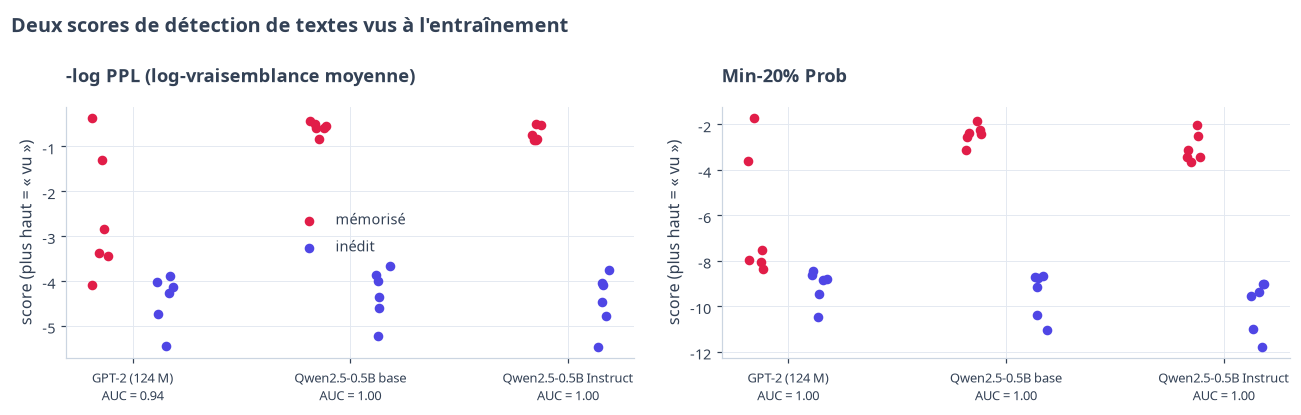

In [23]:
from sklearn.metrics import roc_auc_score

sub = cont[cont.famille != "mélangé"]
aucs = []
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, (col, nom_score) in zip(axes, [("ppl", "-log PPL (log-vraisemblance moyenne)"), ("mink", "Min-20% Prob")]):
    for i, mod in enumerate(MODELES):
        for j, fam in enumerate(["mémorisé", "inédit"]):
            v = sub[(sub.modele == mod) & (sub.famille == fam)][col]
            v = -np.log(v) if col == "ppl" else v
            ax.scatter(np.full(len(v), i + (j - 0.5) * 0.3) + rng.uniform(-0.04, 0.04, len(v)), v,
                       color=fam_col[fam], s=28, label=fam if i == 0 else None, zorder=3)
        g = sub[sub.modele == mod]
        sc = -np.log(g.ppl) if col == "ppl" else g.mink
        aucs.append(roc_auc_score(g.famille == "mémorisé", sc))
    ax.set_xticks(range(len(MODELES)))
    ax.set_xticklabels([f"{m}\nAUC = {a:.2f}" for m, a in zip(MODELES, aucs[-len(MODELES):])], fontsize=8.5)
    ax.set_ylabel("score (plus haut = « vu »)"); ax.set_title(nom_score)
axes[0].legend(loc="center")
finish(fig, "Deux scores de détection de textes vus à l'entraînement")
plt.show()

Sur ce petit échantillon, les deux scores séparent parfaitement les familles pour les
Qwen ; pour GPT-2, qui mémorise moins, la perplexité moyenne commet des erreurs alors que
Min-K% reste au moins aussi bon (l'AUC vaut 1 lorsque tous les textes mémorisés ont un
score supérieur à tous les textes inédits). En pratique, la détection de contamination est plus délicate : les textes d'un
benchmark ne sont pas tous mémorisés mot pour mot, une paraphrase échappe au détecteur, et
il faut un groupe de référence de textes « certainement inédits » de même style (d'où
l'intérêt de comparer, comme ici, des textes appariés). L'exercice 3.4 approfondit la
question avec des textes partiellement modifiés.

> **À retenir.** Une perplexité anormalement basse trahit un texte mémorisé (risque de
> contamination d'un benchmark), une perplexité anormalement haute un texte incohérent ou
> inhabituel. Ces signaux sont utiles pour l'évaluation comme pour le nettoyage de
> données (chapitre 8).

## Synthèse

- Évaluer un modèle de fondation est difficile : tâches ouvertes, modèles opaques et de
  plus en plus capables, benchmarks vite saturés, périmètre sans cesse élargi.
- **Entropie** $H(P)$ : imprévisibilité intrinsèque des données. **Entropie croisée**
  $H(P,Q) = H(P) + D_{KL}(P\|Q) \ge H(P)$ : coût de prédiction du modèle, c'est la perte
  d'entraînement.
- BPC, BPB et perplexité sont des réécritures de la même log-vraisemblance ; seul le BPB
  se compare entre tokenizers ; la perplexité est un nombre effectif de choix.
- La perplexité baisse avec la structure des données et la longueur du contexte, monte
  avec la taille du vocabulaire et souvent après post-entraînement.
- Elle est un **proxy** des capacités d'un modèle de base et un **détecteur** de textes
  mémorisés (contamination, déduplication) ou anormaux.

**Liens.** Le chapitre 2 a introduit l'échantillonnage et les log-probabilités ; le
chapitre 4 utilisera ces métriques pour sélectionner des modèles et parlera de nouveau de
contamination des benchmarks ; le chapitre 7 (quantification) et le chapitre 8 (données)
s'appuient sur la perplexité. Le cours 2 passe à l'évaluation des sorties elles-mêmes :
correction fonctionnelle et similarité avec des références.

In [24]:
llm.free_gpu()